In [1]:
import csv
import biom
from biom import Table
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score

In [2]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.gridspec import GridSpec
from sklearn.metrics import r2_score, mean_absolute_error

In [3]:
from skbio.stats import subsample_counts

# Predicting Host Age from the Oral Microbiome

This notebook builds and evaluates a machine-learning model that predicts a person's
age from their oral microbiome composition. The pipeline goes from raw feature counts
and sample metadata through quality control, a **study-aware cross-validation** scheme,
Random Forest training, and evaluation.

**Key idea:** I train a Random Forest regressor on relative-abundance features and
evaluate it with a **leave-studies-out** design, so performance reflects how well the
model generalizes to *entirely new studies* rather than to new samples from studies it
has already seen.

## Data

Two inputs are used:

- **A feature (BIOM) table** — a matrix of microbial feature counts (genus-level in the
  reported results), samples as columns and microbial features as rows.
- **Sample metadata** (TSV) — one row per sample, including cleaned host age
  (`age_cleaned`), oral site (`site_cleaned`), study/project id (`bioproject_id`), and
  health status (`status_cleaned`).

In [4]:
# table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_output/feature-table.biom")
table

5892 x 93647 <class 'biom.table.Table'> with 5191301 nonzero entries (0% dense)

In [5]:
table.ids(axis="sample")

array(['B1', 'B3', 'B4', ..., '11404.000069119', '11404.000069121',
       '11404.000069122'], dtype='<U28')

In [6]:
# metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata = pd.read_csv("/beegfs/huangxiaochang/global_oral/new_analysis/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
metadata.shape

(44446, 49)

In [7]:
metadata.head()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
0,CNP0002325,B1,B1,1.8,852,125752,0.560900,0.748847,319,5.188369,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
1,CNP0002325,B3,B3,2.2,913,136072,0.540071,0.748847,330,5.245999,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
2,CNP0002325,B4,B4,0.7,444,163914,0.775532,0.748847,209,3.986967,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
3,CNP0002325,B5,B5,2.4,833,133478,0.560014,0.748847,306,5.078915,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
4,CNP0002325,B6,B6,4.9,1371,210064,0.521746,0.748847,455,5.291183,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no


In [8]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'sample_cr_mapping_rate', 'study_cr_mapping_rate',
       'Observed', 'Shannon', 'Simpson', 'InvSimpson', 'Chao1', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'age_cleaned', 'bmi_cleaned', 'age_cleaned_group', 'age_info_cleaned',
       'bmi_cleaned_group', 'sex_cleaned', 'platform_cleaned',
       'sequencing_region_cleaned', 'country_cleaned', 'continent_group',
       'site_cleaned', 'site_group_cleaned', 'disease_study_cleaned',
       'status_cleaned', 'asv_le_30', 'study_asv_lt30_high', 'chim_gt_25',
       'study_chim_gt25_high', 'sample_cr_mapping_low',
       'study_cr_mapping_low'],
      dtype='object')

## Feature-table quality control

Apply QC to the BIOM table to remove noise and low-information samples/features:

1. **Sample matching** — intersect sample IDs present in both metadata and feature table.
2. **Prevalence filtering** — keep features detected in more than 50 samples; rare
   features add noise rather than signal.
3. **Read-depth filtering** — remove samples with fewer than 1,000 total reads, since
   shallow samples give unreliable abundance estimates.

After each step, `remove_empty()` drops any all-zero rows/columns. (Rarefaction to a
fixed depth is available as an optional step but the reported results use
relative-abundance normalization instead.)

In [9]:
metadata = metadata.loc[metadata.age_cleaned > 0]
metadata = metadata.loc[metadata['site'].notna()]
metadata = metadata.loc[metadata.site_cleaned != "other"]
# metadata = metadata.loc[metadata.status_cleaned == "HC"]

In [10]:
metadata.shape

(20314, 49)

In [11]:
metadata.site_cleaned.unique()

array(['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva'],
      dtype=object)

In [12]:
metadata.groupby("site_cleaned").count()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,continent_group,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
site_cleaned,,,,,,,,,,,,,,,,,,,,,
gingiva,103,103,103,103,103,103,103,103,103,103,...,103,103,103,103,103,103,103,103,103,103
oral mucosa,1139,1139,1139,1139,1139,1139,1139,1139,1139,1139,...,1139,1139,1139,1108,1139,1139,1139,1139,1139,1139
oral swab,2767,2767,2767,2767,2767,2767,2767,2767,2767,2767,...,2767,2767,2667,2667,2767,2767,2767,2767,2767,2767
saliva,13987,13987,13987,13987,13987,13987,13987,13987,13987,13987,...,13855,13987,13987,12814,13987,13987,13987,13987,13987,13987
tongue,352,352,352,352,352,352,352,352,352,352,...,352,352,352,349,352,352,352,352,352,352
tooth,1966,1966,1966,1966,1966,1966,1966,1966,1966,1966,...,1966,1966,1966,1935,1966,1966,1966,1966,1966,1966


In [13]:
sid = np.intersect1d(metadata.sample_id.values, table.ids(axis="sample"))

table.filter(sid, axis="sample")
table.remove_empty()

2812 x 20314 <class 'biom.table.Table'> with 1030423 nonzero entries (1% dense)

In [14]:
fid = table.ids(axis="observation")
prevalence = table.nonzero_counts(axis="observation")
table = table.filter(fid[prevalence > 50], axis='observation', inplace=False)
table.remove_empty()

427 x 20314 <class 'biom.table.Table'> with 1012978 nonzero entries (11% dense)

In [15]:
sid_reads = table.sum(axis="sample")
sid = table.ids(axis="sample")
table = table.filter(sid[sid_reads > 1000], axis='sample', inplace=False)
table.remove_empty()

427 x 20297 <class 'biom.table.Table'> with 1012596 nonzero entries (11% dense)

In [16]:
# rarefaction_depth = 1000
# obs_ids         = table.ids(axis='observation')
# rarefied_matrix = []
# samples_to_keep = []

# for sid in table.ids(axis='sample'):
#     counts   = table.data(sid, axis='sample', dense=True).astype(int)
#     rarefied = subsample_counts(counts, n=rarefaction_depth)
#     rarefied_matrix.append(rarefied)
#     samples_to_keep.append(sid)

# matrix = np.array(rarefied_matrix).T
# table  = Table(matrix, obs_ids, samples_to_keep, type="OTU table")
# table  = table.remove_empty(inplace=False)

In [17]:
sid = table.ids(axis="sample")
metadata = metadata.loc[[i in sid for i in metadata.sample_id.values]]

## Study selection per site

For each oral site, keep only the studies (`bioproject_id`) that contribute **more than
10 healthy-control samples**, so every study entering cross-validation has enough
samples to be meaningful.

In [18]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa', 'oral swab', 'gingiva']
for i in oral_sites:
    temp = metadata.loc[metadata.status_cleaned == "HC"]
    temp = temp.loc[temp.site_cleaned.values == i]
    counts = temp.groupby('bioproject_id')['sample_id'].count()
    selected = counts[counts > 10]
    print(len(selected))

49
12
4
5
2
1


### RF difference sites

## Cross-validation: leave-studies-out

The most important design choice is **how the data is split**. Instead of splitting
individual samples at random, I split at the level of **studies (bioprojects)**. Samples
from the same study share sequencing batch, protocol, and cohort characteristics; a
random sample-level split would let the model memorize study-specific signatures and
report over-optimistic accuracy.

For each oral site independently:

1. Collect the qualifying studies for that site.
2. Run K-fold cross-validation over the **studies** (`KFold`, shuffled,
   `random_state=42`), with folds tuned per site.
3. In each fold, some studies form the training set and the held-out studies form the
   test set — so the model is always evaluated on studies it has never seen.

Within each fold:

- The **training set** uses only healthy-control samples from the training studies.
- The **test set** is restricted to the age range seen in training (samples outside it
  are removed) to avoid extrapolation. Folds whose test set becomes empty are skipped.

**Per-fold feature processing:** subset the table to training samples and drop absent
features (this defines the feature vocabulary); subset the test table to the same
features; **normalize to relative abundance** so sequencing depth doesn't dominate;
**align feature columns** by reindexing the test matrix to the training columns (missing
features filled with 0); and align age labels to the exact row order.

**Model:** a **Random Forest regressor** with 500 trees (`n_estimators=500`),
`random_state=42` for reproducibility, and `n_jobs=-1`. For each site/fold I save
per-sample results (sample id, true age, predicted age, error) plus a summary table of
split sizes.

In [19]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
fold_test_studies = {
    'saliva': 5, 'tooth': 5, 'tongue': 4, 'oral mucosa': 5
}

# MAX_SAMPLES_PER_STUDY = 200

OUTPUT_DIR = "../../data/age_prediction/leave_studies_out_rf"
sid_to_age = metadata.set_index('sample_id')['age_cleaned']

records = []

for j in oral_sites:
    metadata_pick = metadata.loc[metadata.site_cleaned == j]

    temp = metadata_pick.loc[metadata_pick.status_cleaned == "HC"]
    counts = temp.groupby('bioproject_id')['sample_id'].count()
    selected = counts[counts > 10].index.values
    metadata_pick = metadata_pick.loc[[i in selected for i in metadata_pick.bioproject_id.values]]
    
    studies = metadata_pick.bioproject_id.unique()
    n_studies = len(studies)

    kf = KFold(n_splits=fold_test_studies[j], shuffle=True, random_state=42)

    for fold, (train_idx, test_idx) in enumerate(kf.split(studies), start=1):

        # -- 1. Split metadata by study ------------------------------------
        train_studies = studies[train_idx]
        test_studies  = studies[test_idx]

        md_train = metadata_pick.loc[
            [i in train_studies for i in metadata_pick.bioproject_id.values]
        ]
        md_train = md_train.loc[md_train.status_cleaned == "HC"]
        md_test  = metadata_pick.loc[
            [i in test_studies for i in metadata_pick.bioproject_id.values]
        ]


        # -- 2. Filter test set to training age range ----------------------
        age_min, age_max = md_train.age_cleaned.min(), md_train.age_cleaned.max()
        n_test_before = md_test.shape[0]
        md_test = md_test.loc[
            (md_test.age_cleaned > age_min) & (md_test.age_cleaned < age_max)
        ]
        n_test_after = md_test.shape[0]

        records.append({
            'site':             j,
            'fold':             fold,
            'n_studies':        n_studies,
            'n_train':          md_train.shape[0],
            'n_test_before':    n_test_before,
            'n_test_after':     n_test_after,
            'train/test ratio': round(md_train.shape[0] / n_test_after, 4)
                                if n_test_after > 0 else None,
        })

        if n_test_after == 0:
            print(f"[SKIP] {j} fold {fold}: test set is empty after age filtering")
            continue

        # -- 3. Filter biom table ------------------------------------------
        train_table = table.filter(md_train.sample_id.values, inplace=False)
        train_table = train_table.remove_empty(inplace=False)

        keep_otus  = train_table.ids(axis='observation')
        test_table = table.filter(md_test.sample_id.values, inplace=False)
        test_table = test_table.filter(keep_otus, axis='observation', inplace=False)

        # -- 4. Normalize to relative abundance ----------------------------
        train_df = train_table.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
        test_df  = test_table.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
        # train_df = train_table.to_dataframe(dense=True).T
        # test_df  = test_table.to_dataframe(dense=True).T

        # -- 5. Align OTU columns, fill missing with 0 --------------------
        test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

        # -- 6. Extract labels aligned to DataFrame row order -------------
        train_label = sid_to_age.reindex(train_df.index).values
        test_label  = sid_to_age.reindex(test_df.index).values

        # -- 7. Train RF model and predict ---------------------------------
        rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
        rf.fit(train_df.values, train_label)
        pred_age = rf.predict(test_df.values)

        # -- 8. Save predictions -------------------------------------------
        site_tag  = j.replace(' ', '_')
        result_df = pd.DataFrame({
            'sample_id': test_df.index,
            'true_age':  test_label,
            'pred_age':  pred_age,
            'error':     pred_age - test_label,
        })
        result_df.to_csv(
            f"{OUTPUT_DIR}/age_predict_test_{fold}_{site_tag}_genus.csv", index=False
        )
        print(f"[OK] {j} fold {fold:2d} | train={md_train.shape[0]:4d}  test={n_test_after:3d}")

# -- Save summary table ----------------------------------------------------
df_results = pd.DataFrame(records)
df_results.to_csv(f"{OUTPUT_DIR}/site_study_split_results_genus.csv", index=False)
print(df_results.to_string(index=False))

[OK] saliva fold  1 | train=8234  test=1302


[OK] saliva fold  2 | train=5410  test=5965


[OK] saliva fold  3 | train=7805  test=1329


[OK] saliva fold  4 | train=6680  test=2685


[OK] saliva fold  5 | train=8087  test=1079


...

[OK] oral mucosa fold  1 | train= 511  test=329


[OK] oral mucosa fold  2 | train= 684  test=161


[OK] oral mucosa fold  3 | train= 821  test= 46


[OK] oral mucosa fold  4 | train= 789  test= 56


[OK] oral mucosa fold  5 | train= 555  test=285
       site  fold  n_studies  n_train  n_test_before  n_test_after  train/test ratio
     saliva     1         49     8234           1302          1302            6.3241
     saliva     2         49     5410           5980          5965            0.9070
     saliva     3         49     7805           1582          1329            5.8728
     saliva     4         49     6680           2685          2685            2.4879
     saliva     5         49     8087           1079          1079            7.4949
      tooth     1         12      942            235           219            4.3014
      tooth     2         12     1037            105           105            9.8762
      tooth     3         12      588            802           793            0.7415
      tooth     4         12     1057             44            44           24.0227
      tooth     5         12      748            571           571            1.3100
     tongue     1

### plot results

## Evaluation

Pool the held-out predictions across all folds for each site and compare predicted vs.
true age, reporting **R²** (variance explained) and **MAE** (mean absolute error, in
years). The scatter plots show predicted vs. true age with a linear fit line and the
ideal 1:1 reference line; here two feature versions are compared side by side for the
saliva and tooth sites.

V1 based on OTU table : biom_oral_qc_dedup.biom  
V2 based on genus table : genus_table_all_qc.qza

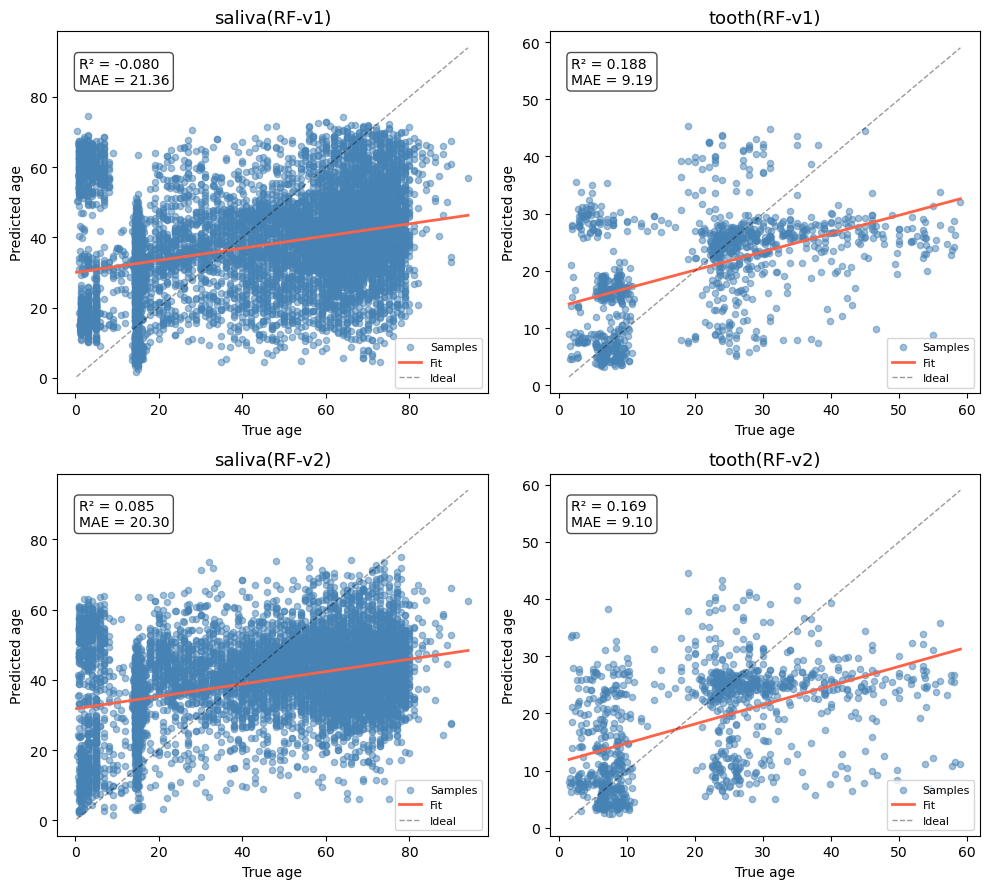

In [478]:
oral_sites = ['saliva', 'tooth']
fold_test_studies = {'saliva': 5, 'tooth': 5}

versions = [
    {'tag': 'RF-v1', 'suffix': ''},
    {'tag': 'RF-v2', 'suffix': '_genus'},
]

def load_site_dfs(suffix):
    site_dfs = {}
    for j in oral_sites:
        site_tag = j.replace(' ', '_')
        dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site_tag}{suffix}.csv")
               for i in range(1, fold_test_studies[j] + 1)]
        dfs = pd.concat(dfs, ignore_index=True)
        site_dfs[j] = dfs.loc[[i in sid_hc for i in dfs.sample_id.values]]
    return site_dfs

nrows = len(versions)      
ncols = len(oral_sites)    
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 9))
axes = np.atleast_2d(axes)  # 保证是二维，便于 [row, col] 索引

for row, ver in enumerate(versions):
    site_dfs = load_site_dfs(ver['suffix'])
    for col, j in enumerate(oral_sites):
        ax = axes[row, col]
        df = site_dfs[j]
        x = df['true_age'].values
        y = df['pred_age'].values
        r2  = r2_score(x, y)
        mae = mean_absolute_error(x, y)

        ax.scatter(x, y, alpha=0.5, s=20, color='steelblue', label='Samples')

        z = np.polyfit(x, y, 1)
        p = np.poly1d(z)
        x_line = np.linspace(x.min(), x.max(), 200)
        ax.plot(x_line, p(x_line), color='tomato', linewidth=2, label='Fit')

        age_min = min(x.min(), y.min())
        age_max = max(x.max(), y.max())
        ax.plot([age_min, age_max], [age_min, age_max], 'k--',
                linewidth=1, alpha=0.4, label='Ideal')

        ax.set_title(f"{j}({ver['tag']})", fontsize=13)
        ax.set_xlabel('True age')
        ax.set_ylabel('Predicted age')
        ax.text(0.05, 0.93, f'R² = {r2:.3f}\nMAE = {mae:.2f}',
                transform=ax.transAxes, fontsize=10,
                verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
        ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('age_prediction_plot.png', dpi=300, bbox_inches='tight')
plt.show()

### Health and disease

In [25]:
metadata = metadata.loc[metadata['status_cleaned'].notna()]
metadata = metadata.loc[metadata.status_cleaned != "Other"]

In [26]:
metadata.status_cleaned.unique()

array(['HC', 'IBD', 'HIV', 'ICU discharge or on ICU day 10', 'ICU',
       'Obesity', 'OSCC', 'Atopic Dermatitis', 'Chagas Disease',
       'Oral Submucous Fibrosis', 'Oral Mucositis',
       'Oral Verrucous Hyperplasia', 'Preterm', 'Periodontal Disease',
       'Dental Caries', 'Oral Lichen Planus', 'Celiac Disease',
       "Sjögren's Syndrome", 'Aphthous',
       'Gastroesophageal Reflux Disease', 'Head and Neck Cancer',
       'COVID-19', 'Lung Cancer', 'Colorectal Cancer',
       'Axial Spondyloarthritis', 'Depression'], dtype=object)

In [27]:
oral_sites = ['saliva', 'tooth', 'tongue', 'oral mucosa']
site_dfs = {}
for j in oral_sites:
    site_tag = j.replace(' ', '_')
    dfs = [pd.read_csv(f"{OUTPUT_DIR}/age_predict_test_{i}_{site_tag}.csv")
           for i in range(1, fold_test_studies[j] + 1)]
    site_dfs[j] = pd.concat(dfs, ignore_index=True).set_index("sample_id")

In [476]:
# def plot_one(ax, df, title):
#     unique = df['status_cleaned'].unique()
#     order  = ['HC'] + sorted([s for s in unique if s != 'HC'])

#     positions = np.arange(1, len(order) + 1)
#     box_data  = [df.loc[df['status_cleaned'] == s, 'MAD'].values for s in order]

#     bp = ax.boxplot(
#         box_data,
#         positions    = positions,
#         widths       = 0.45,
#         patch_artist = True,
#         showfliers   = False,
#         medianprops  = dict(color='black', linewidth=2),
#         whiskerprops = dict(linewidth=1.2, color='black'),
#         capprops     = dict(linewidth=1.2, color='black'),
#         boxprops     = dict(linewidth=1.2),
#     )
#     for patch in bp['boxes']:
#         patch.set_facecolor('white')
#         patch.set_edgecolor('black')

#     for pos, s in zip(positions, order):
#         y = df.loc[df['status_cleaned'] == s, 'MAD'].values
#         x = np.random.uniform(pos - 0.12, pos + 0.12, size=len(y))
#         ax.scatter(x, y, color='black', alpha=0.4, s=4, zorder=3)

#     ax.axhline(0, color='black', linewidth=0.8, linestyle='--', zorder=1)
#     ax.set_xticks(positions)
#     ax.set_xticklabels(order, fontsize=10, rotation=90, ha='center')
#     ax.set_ylabel('MAD', fontsize=10)
#     ax.set_title(title, fontsize=12, fontweight='bold', pad=6)
#     ax.set_xlim(0.4, len(order) + 0.6)
#     ax.spines['top'].set_visible(False)
#     ax.spines['right'].set_visible(False)


# datasets = []
# titles   = []
# for j in oral_sites:
#     metadata_pick = metadata.loc[metadata.site_cleaned == j].set_index("sample_id")
#     metadata_pick.index = metadata_pick.index.astype(str)
#     site_dfs[j].index = site_dfs[j].index.astype(str)
#     inter_sid = np.intersect1d(metadata_pick.index.values, site_dfs[j].index.values)
#     df = site_dfs[j].loc[inter_sid].copy()
#     df["status_cleaned"] = metadata_pick.loc[inter_sid, "status_cleaned"].values
#     df["MAD"] = df.pred_age.values - df.true_age.values
#     datasets.append(df)
#     titles.append(j)

# fig = plt.figure(figsize=(16, 10))
# gs  = GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35,
#                left=0.07, right=0.97, top=0.92, bottom=0.08)

# for idx, (df, title) in enumerate(zip(datasets, titles)):
#     row, col = divmod(idx, 3)
#     ax = fig.add_subplot(gs[row, col])
#     plot_one(ax, df, title)

# plt.show()

In [477]:
# from sklearn.model_selection import KFold, cross_val_predict
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import r2_score, mean_absolute_error

# study_list = ['PRJNA427101', 'PRJNA778006', 'PRJEB35824']
# for study_id in study_list:
#     md_study = metadata.loc[
#         (metadata.site_cleaned == 'saliva') &
#         (metadata.bioproject_id == study_id) &
#         (metadata.status_cleaned == 'HC')
#     ]
    

#     study_table = table.filter(md_study.sample_id.values, inplace=False)
#     study_table = study_table.remove_empty(inplace=False)
#     X = study_table.norm(axis='sample', inplace=False).to_dataframe(dense=True).T
#     y = sid_to_age.reindex(X.index).values
    
#     rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
#     pred = cross_val_predict(rf, X, y, cv=KFold(n_splits=5, shuffle=True, random_state=42))

#     print(f"Project ID: {study_id}")
#     print(f"Number of samples: {md_study.shape[0]}")
#     print(f"Within-study R²  : {r2_score(y, pred):.3f}")
#     print(f"Within-study MAE : {mean_absolute_error(y, pred):.2f}")

Project ID: PRJEB35824
Number of samples: 641
Within-study R²  : 0.855
Within-study MAE : 0.34
